# IND320 — Project Part 4

- **By:** Agop Haroun
- **GitHub repository:** [G0KU-DOTCOM/Streamlit_dashboard](https://github.com/G0KU-DOTCOM/Streamlit_dashboard)
- **Streamlit application:** [ind320dashboard.streamlit.app](https://ind320dashboard.streamlit.app)

### AI usage

Codex helped identify and verify the overlapping test period, implement and test the exchange rate downloader, collect the NO3 source samples, check timestamp conventions, and build and validate the weekly NO3 dataset. It also helped validate the weather sample and implement the lagged correlation. For forecasting, Codex followed the IND320 SNARIMAX example and used the training period and first model orders approved by the author.

## 1. Data preparation

### 1.1 Choose the test region and period

Use **NO3** from **14 October through 29 December 2024**. The project includes hourly ERA5 weather for NO3 throughout 2024. The ENTSO-E snapshot includes the NO3–SE2 connection from 11 October 2024. The chosen period starts with the first complete Monday–Sunday week in the overlap and ends on the last Sunday covered by the 2024 weather file. The local NVE history cache contains one NO3 observation for each week (ISO weeks 42–52), and the local ENTSO-E archive contains 1,849 distinct NO3–SE2 hours in the period.

The period includes the switch to winter time on 27 October and the Christmas holidays. These give us specific dates to inspect when we compare hourly timestamps and currency publication dates. The 11 weeks are a test window for combining the data.

The cell below checks that the selected dates fit inside both existing hourly data ranges. The [weather file](../data/weather/NO3_era5_2024-01-01_2024-12-31_hourly.csv.gz) provides the weather timestamps and the [snapshot plan](../entsoe_plan.json) provides ENTSO-E coverage.

In [1]:
import json
from datetime import date, datetime, time, timedelta
from pathlib import Path
from zoneinfo import ZoneInfo

import pandas as pd

# The notebook can run from the project root or the notebooks folder.
project_root = Path.cwd()
if project_root.name == 'notebooks':
    project_root = project_root.parent

region = 'NO3'
nve_area_type, nve_area_number = 'EL', 3
entsoe_connection = 'NO3-SE2'
test_start = date(2024, 10, 14)
test_last_date = date(2024, 12, 29)
test_end = test_last_date + timedelta(days=1)
assert test_start.weekday() == test_end.weekday() == 0, 'Use whole calendar weeks.'

# Express the chosen local date boundaries as instants to check source coverage.
oslo = ZoneInfo('Europe/Oslo')
window_start = datetime.combine(test_start, time.min, tzinfo=oslo)
window_end = datetime.combine(test_end, time.min, tzinfo=oslo)

with (project_root / 'entsoe_plan.json').open() as f:
    entsoe_plan = json.load(f)
entsoe_start = datetime.fromisoformat(entsoe_plan['period']['start_inclusive'])
entsoe_end = datetime.fromisoformat(entsoe_plan['period']['end_exclusive'])
assert entsoe_start <= window_start < window_end <= entsoe_end
assert any(item['connection'] == entsoe_connection for item in entsoe_plan['connections'])

weather_file = project_root / 'data/weather/NO3_era5_2024-01-01_2024-12-31_hourly.csv.gz'
weather_times = pd.read_csv(weather_file, usecols=['time'], parse_dates=['time'])['time']
assert weather_times.min() <= window_start < window_end <= weather_times.max()

week_count = (test_end - test_start).days // 7
print(f'{region} | {test_start:%d %b} to {test_last_date:%d %b %Y} | {week_count} full weeks')
print(f'Inside the saved weather period and the {entsoe_connection} snapshot period.')

NO3 | 14 Oct to 29 Dec 2024 | 11 full weeks
Inside the saved weather period and the NO3-SE2 snapshot period.


### 1.2 Download EUR and USD exchange rates

The [Norges Bank API](https://www.norges-bank.no/en/topics/Statistics/open-data/guide-data-warehouse/) provides daily EUR/NOK and USD/NOK spot rates. The shared [downloader](../dashboard/exchange_rates.py) requests both series in one call. It checks the currency, units, dates and duplicates, then returns one row per observed date with NOK per euro and NOK per US dollar. The dates are calendar dates from the API.

Use the test period from section 1.1 to verify the download. The Christmas-week table includes all seven dates so the dates with no published rate are visible.

In [2]:
import sys

# Make the project's shared module available when Jupyter starts in notebooks/.
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from dashboard.exchange_rates import download_exchange_rates

# The downloader accepts inclusive dates and keeps the original quote dates.
exchange_rates = download_exchange_rates(test_start, test_last_date)
print(f"Published observations: {exchange_rates['eur_nok'].count()} EUR and "
      f"{exchange_rates['usd_nok'].count()} USD")
exchange_rates.head()

Published observations: 52 EUR and 52 USD


,eur_nok,usd_nok
date,,
2024-10-14,11.7465,10.7618
2024-10-15,11.7660,10.7915
2024-10-16,11.8015,10.8300
2024-10-17,11.8735,10.9272
2024-10-18,11.8115,10.8892


In [3]:
# Add calendar dates to this display only so missing quotes stay visible.
christmas_days = pd.date_range('2024-12-23', '2024-12-29', name='date')
exchange_rates.reindex(christmas_days)

,eur_nok,usd_nok
date,,
2024-12-23,11.8070,11.3605
2024-12-24,NaN,NaN
2024-12-25,NaN,NaN
2024-12-26,NaN,NaN
2024-12-27,11.8435,11.3498
2024-12-28,NaN,NaN
2024-12-29,NaN,NaN


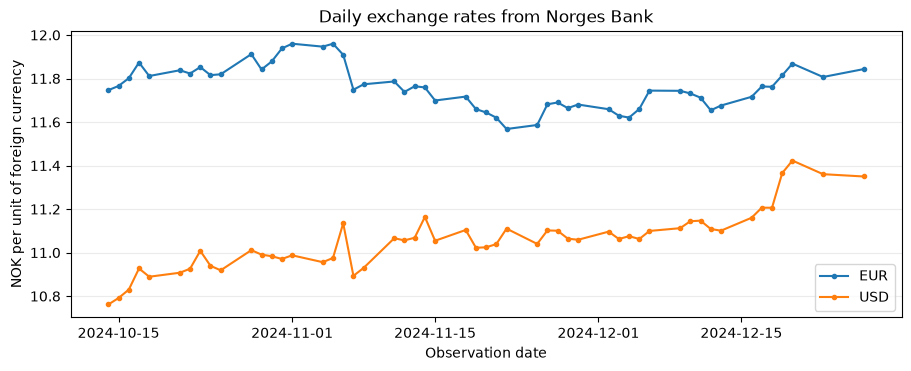

In [4]:
import matplotlib.pyplot as plt

# Mark the observation dates so published quotes are visible on the plot.
fig, ax = plt.subplots(figsize=(9, 3.6), layout='constrained')
ax.plot(exchange_rates.index, exchange_rates['eur_nok'], marker='.', label='EUR')
ax.plot(exchange_rates.index, exchange_rates['usd_nok'], marker='.', label='USD')
ax.set(title='Daily exchange rates from Norges Bank', xlabel='Observation date',
       ylabel='NOK per unit of foreign currency')
ax.legend()
ax.grid(axis='y', alpha=0.25)
plt.show()

In the week of 23–29 December 2024, both series have quotes on 23 and 27 December. The weekly dataset will use the actual quote dates when it counts valid observations and aggregates the rates.

### 1.3 Load the NO3 source samples

Use the test period from section 1.1 for all three sources. Keep the NVE dates and the hourly timestamps from the source readers for inspection in the time-alignment section.

#### NVE Magasinstatistikk

Fetch NVE's public history with the [existing API reader](../dashboard/load_data.py) and select the NO3 price area. Keep the API's ISO year, ISO week, observation date and next-publication field alongside the filling measurements.

In [5]:
from dashboard.load_data import MAX_HISTORY_BYTES, fetch_json, prepare_history

# Keep the raw API response available for inspecting the original date fields.
nve_records, _ = fetch_json('HentOffentligData', MAX_HISTORY_BYTES)
nve_history = prepare_history(nve_records)
nve_selection = (
    nve_history['area_type'].eq(nve_area_type)
    & nve_history['area_number'].eq(nve_area_number)
    & nve_history['observation_date'].between(pd.Timestamp(test_start), pd.Timestamp(test_end), inclusive='left')
)
nve_weekly = nve_history.loc[nve_selection, [
    'observation_date', 'iso_year', 'iso_week', 'filling_fraction',
    'weekly_filling_change', 'next_publication_date',
]].reset_index(drop=True)
print(f'NVE returned {len(nve_weekly)} weekly observations for {region}.')
nve_weekly.head(3)

NVE returned 11 weekly observations for NO3.


,observation_date,iso_year,iso_week,filling_fraction,weekly_filling_change,next_publication_date
0,2024-10-20,2024,42,0.870708,0.004746,2024-10-30 13:00:00
1,2024-10-27,2024,43,0.905651,0.034929,2024-11-06 13:00:00
2,2024-11-03,2024,44,0.923453,0.017802,2024-11-13 13:00:00


#### Open-Meteo ERA5

Reuse the [saved NO3 hourly summary](../data/weather/NO3_era5_2024-01-01_2024-12-31_hourly.csv.gz) from Part 3. Each record includes the UTC timestamp, regional means for temperature and precipitation, and the number of sampled locations.

In [6]:
from dashboard.weather_data import read_weather_summary

# Validate the saved calendar-year summary before taking the sample.
weather_year = test_start.year
weather_history = read_weather_summary(region, date(weather_year, 1, 1), date(weather_year, 12, 31))
if weather_history is None:
    raise FileNotFoundError(f'The saved ERA5 summary for {region} in {weather_year} is missing.')
weather_selection = weather_history['time'].between(window_start, window_end, inclusive='left')
weather_hourly = weather_history.loc[weather_selection].reset_index(drop=True)
print(f'{len(weather_hourly):,} weather hours for {region}.')
weather_hourly.head(3)

1,849 weather hours for NO3.


,time,temperature_2m,precipitation,point_count
0,2024-10-13 22:00:00+00:00,3.7097,0.6045,1000
1,2024-10-13 23:00:00+00:00,3.5154,0.5293,1000
2,2024-10-14 00:00:00+00:00,3.3849,0.4395,1000


#### ENTSO-E transfers in MongoDB

Use the app's [read-only query](../dashboard/transfers.py) to load the saved 2024 data for NO3–SE2, then select the test period. A complete hour has a full 60 minutes of coverage and a valid energy value in each direction. The MongoDB connection reads the URI from the local `.streamlit/secrets.toml` file.

In [7]:
from dashboard.transfers import COLLECTION, DATABASE, complete_hours, read_year
from pipeline.entsoe_mongo import connect

# Use the existing MongoDB connection and bounded query for a single border and year.
with connect(project_root) as client:
    entsoe_history = read_year(client[DATABASE][COLLECTION], entsoe_connection, test_start.year)
entsoe_selection = (entsoe_history.index >= window_start) & (entsoe_history.index < window_end)
entsoe_hourly = entsoe_history.loc[entsoe_selection].copy()
complete = complete_hours(entsoe_hourly).sum()
print(f'{entsoe_connection} has {complete:,} of {len(entsoe_hourly):,} complete hours in the test period.')
entsoe_hourly.head(3)

NO3-SE2 has 1,849 of 1,849 complete hours in the test period.


,import_mwh,export_mwh,import_coverage_minutes,export_coverage_minutes
time_utc,,,,
2024-10-13 22:00:00+00:00,0.0,50.61,60.0,60.0
2024-10-13 23:00:00+00:00,0.0,69.85,60.0,60.0
2024-10-14 00:00:00+00:00,0.0,55.95,60.0,60.0


### 1.4 Investigate time zones and publication dates

| Source | Example from the project data | What the time represents |
| --- | --- | --- |
| NVE Magasinstatistikk | `dato_Id` is `2024-10-27`, ISO week 43 | Norwegian Sunday date. The reference is the end of Sunday (Monday 00:00). NVE can use an earlier measurement if the reference-time measurement is unavailable. |
| ENTSO-E | `time_utc` is `2024-10-13 22:00Z` in MongoDB | UTC start of the hour whose import and export energy are stored in MWh. This is Monday 14 October at 00:00 in Oslo. |
| Open-Meteo ERA5 | `time` is `2024-10-13 22:00Z` in the saved data | We requested GMT. Temperature is at the timestamp. Precipitation is the total for the hour ending at that timestamp. |
| Norges Bank | `TIME_PERIOD` is `2024-12-23` | Calendar date of the EUR and USD quotes. The CSV row contains a date with no time of day or offset. |

[NVE handbook](https://webfileservice.nve.no/API/PublishedFiles/Download/64edbe40-b965-4c90-a114-88162ffff454/201903383/3435075) · [ENTSO-E response times](https://transparencyplatform.zendesk.com/hc/en-us/articles/12786431986964-Response-Time-Zone) · [Hourly transfer processing](../pipeline/entsoe_hourly.py) · [Open-Meteo archive](https://open-meteo.com/en/docs/historical-weather-api) · [Norges Bank API guide](https://www.norges-bank.no/en/topics/Statistics/open-data/guide-data-warehouse/)

#### When the values become available

- **NVE.** The usual release is Wednesday at 13:00 Norwegian time. The week 43 API row points to **6 November** in `neste_Publiseringsdato`. The previous row points to **30 October at 13:00**. NVE's week 43 article is dated 29 October and was updated on 30 October. This gives us a scheduled release and article dates. The exact first API availability is unknown. At year-end, NVE explicitly scheduled week 52 for **2 January 2025 at 13:00** and its report is dated 2 January. We keep that release separate from the observation date of 29 December 2024. [Week 43 report](https://www.nve.no/nytt-fra-nve/rapporter-vassmagasinstatistikk/vassmagasinstatistikk-veke-43-2024/) · [Week 52 announcement](https://www.nve.no/nytt-fra-nve/rapporter-vassmagasinstatistikk/vassmagasinstatistikk-veke-51-2024/) · [Week 52 report](https://www.nve.no/nytt-fra-nve/rapporter-vassmagasinstatistikk/vassmagasinstatistikk-veke-52-2024/)
- **ENTSO-E.** The MongoDB snapshot keeps measurement hours and coverage. It has no publication or revision timestamps per hour. [Transfer data layout](../entsoe_plan.json)
- **Open-Meteo.** The documented ERA5 archive delay is about five days. A full week of ERA5 can therefore be unavailable when the NVE value for that week is published. [Open-Meteo dataset availability](https://open-meteo.com/en/docs/historical-weather-api#data-sources)
- **Norges Bank.** The bank lists approximate publication at 16:00 CET on business days. We retain the quote date and leave days without a quote missing. The Christmas example in section 1.2 shows only two quote dates, 23 and 27 December. [Norges Bank FAQ](https://www.norges-bank.no/en/topics/statistics/exchange_rates/valutakursar-faq/)

#### Check the autumn clock change

Keep hourly timestamps in UTC and define the week as Monday 00:00 up to the next Monday 00:00 in `Europe/Oslo`. For precipitation, use the start of its one-hour interval, one hour before its reported timestamp. Keep the original weather timestamps for reference. The sample below checks complete hourly coverage against an independently generated UTC grid for NVE week 43.

In [8]:
# Convert both local week boundaries to UTC before building the hourly grid.
clock_week_start = pd.Timestamp('2024-10-21', tz=oslo).tz_convert('UTC')
clock_week_end = pd.Timestamp('2024-10-28', tz=oslo).tz_convert('UTC')
expected_hours = pd.date_range(clock_week_start, clock_week_end, freq='h', inclusive='left')

# The full weather file also contains the report for the final precipitation hour.
weather_utc = pd.DatetimeIndex(weather_history['time'])
one_hour = pd.Timedelta(hours=1)
precipitation_start_utc = weather_utc - one_hour
clock_temperature = weather_utc[(weather_utc >= clock_week_start) & (weather_utc < clock_week_end)]
clock_precipitation = precipitation_start_utc[
    (precipitation_start_utc >= clock_week_start) & (precipitation_start_utc < clock_week_end)
]
clock_transfers = entsoe_hourly.loc[
    (entsoe_hourly.index >= clock_week_start) & (entsoe_hourly.index < clock_week_end)
]

assert len(expected_hours) == 169
assert clock_temperature.equals(expected_hours) and clock_precipitation.equals(expected_hours)
assert clock_transfers.index.equals(expected_hours) and complete_hours(clock_transfers).all()
print('Week 43: 169 hours each for temperature, precipitation and complete transfers.')

# Both occurrences of 02:00 are valid hours and have different UTC offsets.
local_hours = expected_hours.tz_convert(oslo)
repeated_hour = local_hours[local_hours.strftime('%Y-%m-%d %H:%M') == '2024-10-27 02:00']
assert len(repeated_hour) == 2 and repeated_hour.is_unique
pd.DataFrame({'UTC': repeated_hour.tz_convert('UTC'), 'Europe/Oslo': repeated_hour})

Week 43: 169 hours each for temperature, precipitation and complete transfers.


,UTC,Europe/Oslo
0,2024-10-27 00:00:00+00:00,2024-10-27 02:00:00+02:00
1,2024-10-27 01:00:00+00:00,2024-10-27 02:00:00+01:00


#### Check midnight and the ISO year boundary

A temperature reading or transfer hour at Monday 00:00 belongs to the new week. The precipitation reported at that same time belongs to the Sunday hour just ended. On 30 December 2024 the new week is ISO week **2025-W01**, even though the calendar date is in 2024. Use ISO year together with ISO week when matching weekly data.

In [9]:
def oslo_iso_week(timestamps):
    # ISO year can differ from calendar year around New Year.
    iso = timestamps.tz_convert(oslo).isocalendar()
    return [f'{year}-W{week:02d}' for year, week in zip(iso['year'], iso['week'])]

# Match the NVE labels to their date fields before using them as week keys.
nve_iso = nve_weekly['observation_date'].dt.isocalendar()
assert nve_iso['year'].eq(nve_weekly['iso_year']).all()
assert nve_iso['week'].eq(nve_weekly['iso_week']).all()

boundary_times = pd.to_datetime([window_start, clock_week_end, window_end], utc=True)
assert boundary_times.isin(weather_utc).all()
temperature_and_transfer_weeks = oslo_iso_week(boundary_times)
precipitation_weeks = oslo_iso_week(boundary_times - one_hour)
assert temperature_and_transfer_weeks == ['2024-W42', '2024-W44', '2025-W01']
assert precipitation_weeks == ['2024-W41', '2024-W43', '2024-W52']

pd.DataFrame({
    'Local boundary': boundary_times.tz_convert(oslo),
    'Temperature / transfer week': temperature_and_transfer_weeks,
    'Precipitation week': precipitation_weeks,
})

,Local boundary,Temperature / transfer week,Precipitation week
0,2024-10-14 00:00:00+02:00,2024-W42,2024-W41
1,2024-10-28 00:00:00+01:00,2024-W44,2024-W43
2,2024-12-30 00:00:00+01:00,2025-W01,2024-W52


#### Rules for the weekly dataset

Use NVE's ISO year and week for filling and Oslo calendar weeks for the other sources. Use the start of each hourly interval for ENTSO-E and precipitation, the observed hour for temperature, and the calendar quote date for exchange rates. Determine expected coverage from the actual local week boundaries. For forecasting, separately check which observations could have been available at each cutoff. The historical samples support alignment by observation time. Recreating exact past release times requires publication history.

### 1.5 Build the weekly NO3 dataset

Keep one NVE filling observation per ISO year and week as the target. For each week, average the hourly temperatures, sum the hourly precipitation and transfer energy, and average each exchange rate over its observed quote days. Filling is a fraction (0.90 means 90%), precipitation is in mm, and transfer energy is in MWh for NO3–SE2.

Count the available hours for each hourly variable. Leave its weekly value missing if any expected hour is missing. For the currencies, count the dates with a quote for each series and check whether both series have a value for every returned date. Holiday weeks can have fewer quote days.

In [10]:
week_columns = ['iso_year', 'iso_week']


def group_by_iso_week(frame, calendar_dates):
    # Use Oslo timestamps for hourly sources and calendar dates for exchange rates.
    iso = calendar_dates.isocalendar()
    year = pd.Index(iso['year'], name='iso_year')
    week = pd.Index(iso['week'], name='iso_week')
    return frame.groupby([year, week])


# The grid uses UTC intervals between the two Oslo boundaries and includes both 02:00 hours.
hour_grid = pd.date_range(
    pd.Timestamp(window_start).tz_convert('UTC'), pd.Timestamp(window_end).tz_convert('UTC'),
    freq='h', inclusive='left', name='time_utc',
)
temperature = weather_hourly.set_index('time')['temperature_2m']
# Use the full weather file for precipitation reported at the final midnight.
precipitation = weather_history.set_index(precipitation_start_utc)['precipitation']
hourly_inputs = pd.DataFrame({
    'temperature_c': temperature,
    'precipitation_mm': precipitation,
    'import_mwh': entsoe_hourly['import_mwh'],
    'export_mwh': entsoe_hourly['export_mwh'],
}, index=hour_grid)

# The transfer reader already leaves partly covered hours missing by direction.
hourly_groups = group_by_iso_week(hourly_inputs, hour_grid.tz_convert(oslo))
expected_week_hours = hourly_groups.size().rename('expected_hours')
hour_counts = hourly_groups.count()
complete_by_variable = hour_counts.eq(expected_week_hours, axis=0)

temperature_weekly = hourly_groups['temperature_c'].mean().to_frame()
totals_weekly = hourly_groups[['precipitation_mm', 'import_mwh', 'export_mwh']].sum(min_count=1)
# Only publish a weekly statistic when the variable covers the entire week.
hourly_weekly = temperature_weekly.join(totals_weekly).where(complete_by_variable)
hourly_weekly = hourly_weekly.join(expected_week_hours).join(hour_counts.rename(columns={
    'temperature_c': 'temperature_hours', 'precipitation_mm': 'precipitation_hours',
    'import_mwh': 'import_hours', 'export_mwh': 'export_hours',
}))
hourly_weekly['hourly_complete'] = complete_by_variable.all(axis=1)

In [11]:
# Group the published quote dates directly by ISO year and week.
quote_groups = group_by_iso_week(exchange_rates, exchange_rates.index)
quote_counts = quote_groups.count()
quote_dates = quote_groups.size().rename('fx_quote_days')
fx_weekly = quote_groups.mean().join(quote_dates).join(quote_counts.rename(columns={
    'eur_nok': 'eur_quote_days', 'usd_nok': 'usd_quote_days',
}))
fx_weekly['both_rates_each_quote_day'] = quote_counts.eq(quote_dates, axis=0).all(axis=1)

# A left join keeps every NVE observation even if a predictor week is absent.
weekly_no3 = nve_weekly.join(hourly_weekly, on=week_columns, validate='one_to_one')
weekly_no3 = weekly_no3.join(fx_weekly, on=week_columns, validate='one_to_one')
fx_count_columns = ['fx_quote_days', 'eur_quote_days', 'usd_quote_days']
weekly_no3[fx_count_columns] = weekly_no3[fx_count_columns].fillna(0).astype(int)
weekly_no3['both_rates_each_quote_day'] = weekly_no3['both_rates_each_quote_day'].eq(True)

# Round for display. Retain full precision in weekly_no3.
value_columns = ['filling_fraction', 'temperature_c', 'precipitation_mm', 'import_mwh', 'export_mwh', 'eur_nok', 'usd_nok']
weekly_no3.set_index(week_columns)[value_columns].round(3)

filling_fraction  temperature_c  precipitation_mm  \
iso_year iso_week                                                      
2024     42                   0.871          7.441            18.993   
         43                   0.906          7.536            79.830   
         44                   0.923          3.189            99.562   
         45                   0.933          5.174            13.153   
         46                   0.940          4.554            71.253   
         47                   0.919         -3.425            34.104   
         48                   0.907          1.533            54.885   
         49                   0.893         -0.488            19.901   
         50                   0.864          0.772            61.222   
         51                   0.847          0.251            60.503   
         52                   0.861          2.450            76.867   

                   import_mwh  export_mwh  eur_nok  usd_nok  
iso_year iso_week                                            
2024     42         80820.805     2588.87   11.800   10.840  
         43         79247.128     3903.51   11.830   10.940  
         44         54783.078     5535.35   11.906   10.989  
         45         26034.152    14999.03   11.868   10.978  
         46         16794.570    22078.93   11.750   11.082  
         47         45894.558    18947.59   11.642   11.060  
         48         47995.365    10343.99   11.660   11.073  
         49         25544.628    14669.76   11.663   11.079  
         50         27970.550    25226.46   11.703   11.123  
         51         48595.315    24524.65   11.785   11.272  
         52         60526.730    18650.22   11.825   11.355

In [12]:
# Show the row counts used for the weekly statistics.
coverage_columns = [
    'expected_hours', 'temperature_hours', 'precipitation_hours', 'import_hours', 'export_hours',
    'hourly_complete', 'eur_quote_days', 'usd_quote_days', 'both_rates_each_quote_day',
]
weekly_no3.set_index(week_columns)[coverage_columns]

expected_hours  temperature_hours  precipitation_hours  \
iso_year iso_week                                                           
2024     42                   168                168                  168   
         43                   169                169                  169   
         44                   168                168                  168   
         45                   168                168                  168   
         46                   168                168                  168   
         47                   168                168                  168   
         48                   168                168                  168   
         49                   168                168                  168   
         50                   168                168                  168   
         51                   168                168                  168   
         52                   168                168                  168   

                   import_hours  export_hours  hourly_complete  \
iso_year iso_week                                                
2024     42                 168           168             True   
         43                 169           169             True   
         44                 168           168             True   
         45                 168           168             True   
         46                 168           168             True   
         47                 168           168             True   
         48                 168           168             True   
         49                 168           168             True   
         50                 168           168             True   
         51                 168           168             True   
         52                 168           168             True   

                   eur_quote_days  usd_quote_days  both_rates_each_quote_day  
iso_year iso_week                                                             
2024     42                     5               5                       True  
         43                     5               5                       True  
         44                     5               5                       True  
         45                     5               5                       True  
         46                     5               5                       True  
         47                     5               5                       True  
         48                     5               5                       True  
         49                     5               5                       True  
         50                     5               5                       True  
         51                     5               5                       True  
         52                     2               2                       True

### 1.6 Check data quality and available history

Verify the weekly join before using it in the analyses. Then count available weeks and the longest consecutive run for each combination of data sources. In the report below, dates span the Monday of the first week to the Sunday of the last week in the run.

In [13]:
# The joined rows must match the expected test weeks and retain the original NVE target.
test_weeks = pd.MultiIndex.from_frame(weekly_no3[week_columns])
assert test_weeks.is_unique and list(test_weeks) == list(expected_week_hours.index)
assert weekly_no3['filling_fraction'].equals(nve_weekly['filling_fraction'])

for measure, count in zip(
    ['temperature_c', 'precipitation_mm', 'import_mwh', 'export_mwh'],
    ['temperature_hours', 'precipitation_hours', 'import_hours', 'export_hours'],
):
    assert weekly_no3[count].between(0, weekly_no3['expected_hours']).all()
    # A missing hour leaves that variable's weekly statistic missing.
    assert weekly_no3[measure].notna().eq(weekly_no3[count].eq(weekly_no3['expected_hours'])).all()

coverage = weekly_no3.set_index(week_columns)
assert coverage.loc[(2024, 43), 'expected_hours'] == 169
assert coverage.loc[(2024, 52), ['eur_quote_days', 'usd_quote_days']].eq(2).all()
assert weekly_no3[['eur_quote_days', 'usd_quote_days']].sum().to_list() == exchange_rates.count().to_list()
print(f'{len(test_weeks)} unique weeks with their original NVE filling values.')
print(f"{weekly_no3['hourly_complete'].sum()} weeks with full weather and transfer coverage.")
print('Week 43 has 169 expected hours. Week 52 has two quote dates per currency.')

11 unique weeks with their original NVE filling values.
11 weeks with full weather and transfer coverage.
Week 43 has 169 expected hours. Week 52 has two quote dates per currency.


In [14]:
# Use the full NVE history and saved ERA5 file to measure coverage beyond the test period.
no3_history = nve_history.loc[
    nve_history['area_type'].eq(nve_area_type) & nve_history['area_number'].eq(nve_area_number)
].copy()
nve_weeks = pd.MultiIndex.from_frame(no3_history.loc[no3_history['filling_fraction'].notna(), week_columns])
assert nve_weeks.is_unique

def weekly_weather(hourly_weather):
    # Use UTC hour starts for alignment, and Oslo Mondays for the reporting weeks.
    hourly = hourly_weather.set_index('time')
    precipitation_starts = hourly.index - one_hour
    first_day = precipitation_starts[0].tz_convert(oslo).normalize()
    last_day = hourly.index[-1].tz_convert(oslo).normalize()
    first_monday = first_day - pd.DateOffset(days=first_day.weekday())
    last_boundary = last_day + pd.DateOffset(days=7 - last_day.weekday())
    grid = pd.date_range(first_monday.tz_convert('UTC'), last_boundary.tz_convert('UTC'),
                         freq='h', inclusive='left')

    # A precipitation record describes the preceding hour. Use its interval start.
    weather_inputs = pd.DataFrame({
        'temperature_c': hourly['temperature_2m'],
        'precipitation_mm': hourly['precipitation'].set_axis(precipitation_starts),
    }, index=grid)
    groups = group_by_iso_week(weather_inputs, grid.tz_convert(oslo))
    complete = groups.count().eq(groups.size(), axis=0)
    weekly = groups['temperature_c'].mean().to_frame().join(
        groups['precipitation_mm'].sum(min_count=1)
    )
    return weekly.where(complete)


weather_weekly_2024 = weekly_weather(weather_history)
nve_weather_weeks = nve_weeks.intersection(weather_weekly_2024.dropna().index)

# Full overlap uses the assembled test weeks with complete hourly data and paired FX quotes.
verified_overlap = weekly_no3['hourly_complete'] & weekly_no3['both_rates_each_quote_day']
all_sources_weeks = test_weeks[verified_overlap]


def coverage_summary(week_keys):
    # ISO Mondays are spaced by exactly seven calendar days in a consecutive run.
    starts = pd.Series(pd.to_datetime([date.fromisocalendar(year, week, 1) for year, week in week_keys]))
    if starts.empty:
        return {'Weeks': 0, 'Longest run': 0, 'From': None, 'Through': None}
    starts = starts.sort_values(ignore_index=True)
    run_number = starts.diff().ne(pd.Timedelta(days=7)).cumsum()
    runs = starts.groupby(run_number).agg(['size', 'min', 'max'])
    longest = runs.loc[runs['size'].idxmax()]
    return {
        'Weeks': len(starts),
        'Longest run': int(longest['size']),
        'From': longest['min'].date(),
        'Through': (longest['max'] + pd.Timedelta(days=6)).date(),
    }


coverage_report = pd.DataFrame.from_dict({
    'NVE filling': coverage_summary(nve_weeks),
    'NVE filling and complete 2024 weather': coverage_summary(nve_weather_weeks),
    'All four sources in the verified overlap': coverage_summary(all_sources_weeks),
}, orient='index').rename_axis('Data available for NO3')
coverage_report

,Weeks,Longest run,From,Through
Data available for NO3,,,,
NVE filling,1663,1663,1995-01-02,2026-11-15
NVE filling and complete 2024 weather,51,51,2024-01-08,2024-12-29
All four sources in the verified overlap,11,11,2024-10-14,2024-12-29


#### What the coverage allows

The saved weather data cover 2024 in UTC. The first Norwegian week starts an hour before the first temperature record, so complete weather weeks start on 8 January. The NO3–SE2 snapshot starts in October 2024, which brings the verified overlap across all four sources down to the 11 test weeks.

Use the long NVE series for a filling-only forecast benchmark. The saved weather can support the first exploratory lag analysis. The next section extends the NO3 weather series through 2023–2025 for tests across several seasons. An experiment using all four sources needs complete weather and quote coverage within the NO3–SE2 snapshot period. Compare models on the same forecast dates and use the coverage checks above before choosing dates.

## 2. Weather and reservoir filling

### Extend the NO3 weather history

The [three-year ERA5 summary](../data/weather/NO3_era5_2023-2025_hourly_sample100.csv.gz) uses the same 100 sampled NO3 locations in 2023, 2024 and 2025. The smaller sample limits the number of requests. To check how closely it tracks the original 1,000-point series, compare their weekly temperature means and precipitation totals over the 51 complete weeks available in the original 2024 file.

To reproduce the sample, sort the NO3 point IDs from `data/geography/weather_locations.csv` and draw 100 with `Random(320).sample(ids, 100)`. Pass those IDs to `download_weather` with `hourly=True` and `batch_size=50` for each calendar year. The local Part 3 point data provided 2024. The archive provided 2023 and 2025. The saved file contains the hourly regional means and point counts. [Open-Meteo archive](https://open-meteo.com/en/docs/historical-weather-api) · [API limits](https://open-meteo.com/en/terms) · [Project downloader](../dashboard/weather_data.py)

In [15]:
forecast_weather_file = project_root / 'data/weather/NO3_era5_2023-2025_hourly_sample100.csv.gz'
forecast_weather = pd.read_csv(forecast_weather_file, parse_dates=['time'])
expected_weather_hours = pd.date_range('2023-01-01', '2026-01-01', freq='h', inclusive='left', tz='UTC')
assert pd.DatetimeIndex(forecast_weather['time']).equals(expected_weather_hours)
assert forecast_weather['point_count'].eq(100).all() and not forecast_weather.isna().any().any()

weather_weekly_3_years = weekly_weather(forecast_weather)
reference_2024 = weather_weekly_2024.dropna()
errors = weather_weekly_3_years.loc[reference_2024.index].sub(reference_2024).abs()
print(f'{len(forecast_weather):,} hours from the same 100 locations in 2023–2025.')
pd.DataFrame({'Mean absolute error': errors.mean(), 'Largest absolute error': errors.max()}).round(2)

26,304 hours from the same 100 locations in 2023–2025.


,Mean absolute error,Largest absolute error
temperature_c,0.14,0.36
precipitation_mm,0.79,3.11


### Sliding-window correlation with weekly filling change

Compare each weather property with NVE's weekly change in NO3 filling. A positive lag of one week pairs a weather value with the following week's filling change. The Pearson correlation uses a trailing window ending on the displayed date. Each estimate requires a full window of valid pairs. [Course chapter on lagged correlation](https://github.com/khliland/IND320/blob/main/D2Dbook/4_Machine_Learning/2_Forecasting/2_ML_approach.ipynb)

In [16]:
def sliding_weather_correlation(weekly, weather_property, lag_weeks, window_weeks):
    # Reinsert gaps so shifting by one position means exactly one calendar week.
    aligned = weekly.sort_index().asfreq('W-SUN')
    lagged_weather = aligned[weather_property].shift(lag_weeks)
    return lagged_weather.rolling(window_weeks).corr(aligned['weekly_filling_change'])


filling_change = no3_history.set_index(week_columns)[['observation_date', 'weekly_filling_change']]
correlation_2024 = reference_2024.join(filling_change, how='inner').set_index('observation_date')
correlation_3_years = weather_weekly_3_years.dropna().join(filling_change, how='inner').set_index('observation_date')
print(f'{len(correlation_2024)} complete weather and reservoir weeks in the 2024 reference.')
print(f'{len(correlation_3_years)} in the extended series.')

settings = [(8, 0), (13, 0), (13, 1), (26, 1)]
properties = {'temperature_c': 'Temperature', 'precipitation_mm': 'Precipitation'}
results = []
for name, weekly, trials in [('2024', correlation_2024, [(13, 1)]),
                             ('2023–2025', correlation_3_years, settings)]:
    for column, label in properties.items():
        for window, lag in trials:
            r = sliding_weather_correlation(weekly, column, lag, window).dropna()
            results.append({
                'Period': name, 'Weather': label, 'Window in weeks': window, 'Lag in weeks': lag,
                'Windows': len(r), 'Lowest r': r.min(), 'Highest r': r.max(),
            })
pd.DataFrame(results).round(2)

51 complete weather and reservoir weeks in the 2024 reference.
156 in the extended series.


,Period,Weather,Window in weeks,Lag in weeks,Windows,Lowest r,Highest r
0,2024,Temperature,13,1,38,-0.49,0.82
1,2024,Precipitation,13,1,38,-0.59,0.03
2,2023–2025,Temperature,8,0,149,-0.85,0.94
3,2023–2025,Temperature,13,0,144,-0.68,0.96
4,2023–2025,Temperature,13,1,143,-0.62,0.85
5,2023–2025,Temperature,26,1,130,-0.31,0.81
6,2023–2025,Precipitation,8,0,149,-0.74,1.00
7,2023–2025,Precipitation,13,0,144,-0.55,0.93
8,2023–2025,Precipitation,13,1,143,-0.73,0.64
9,2023–2025,Precipitation,26,1,130,-0.60,0.48


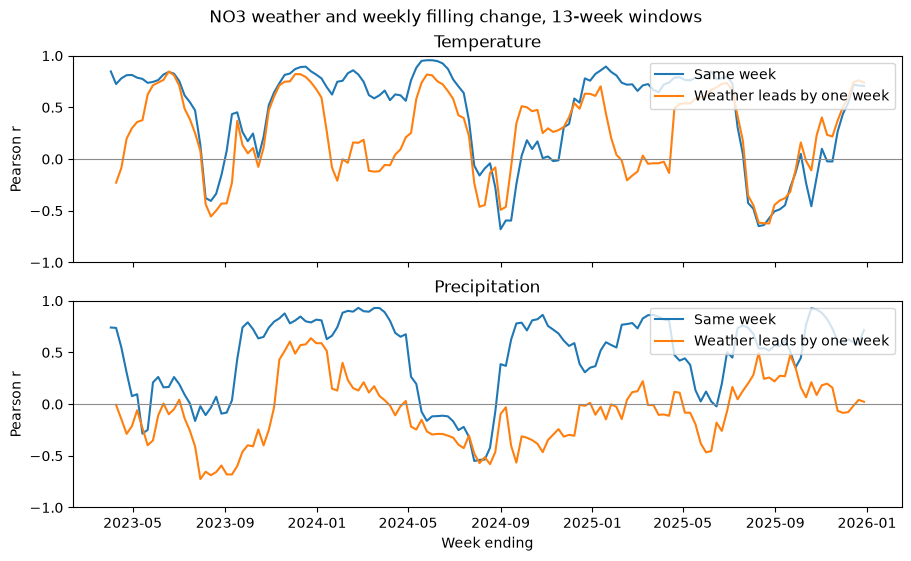

In [17]:
# Compare same-week and one-week leads at a fixed window on the same sample.
window_weeks = 13
fig, axes = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True, layout='constrained')
for ax, (column, label) in zip(axes, properties.items()):
    for lag in (0, 1):
        r = sliding_weather_correlation(correlation_3_years, column, lag, window_weeks)
        ax.plot(r.index, r, label='Same week' if lag == 0 else 'Weather leads by one week')
    ax.axhline(0, color='0.55', linewidth=0.8)
    ax.set(title=label, ylabel='Pearson r', ylim=(-1, 1))
    ax.legend(loc='upper right')
axes[-1].set_xlabel('Week ending')
fig.suptitle('NO3 weather and weekly filling change, 13-week windows')
plt.show()

#### Initial correlation findings

In the 13-week same-week comparison, temperature correlation fell from **0.96** in the window ending 2 June 2024 to **−0.68** in the window ending 1 September. With temperature one week ahead, increasing the window from 13 to 26 weeks changed the observed range from about **−0.62 to 0.85** to **−0.31 to 0.81**.

Precipitation also changed sign over time. With a 13-week window, its highest same-week correlation was **0.93**, and the highest one-week lead correlation was **0.64**. The change in sign and the weaker lead correlations make chronological backtesting important. Compare candidate weather inputs with a filling-only model and check when each input would have been available at the forecast date.

## 3. Reservoir forecasting with River SNARIMAX

### 3.1 First filling-only forecast

Follow the learn-one loop in the course's River example. For this first NO3 experiment, use **8 January 2023–5 October 2025** as training, then predict **12 weekly observations**, from **12 October through 28 December 2025**. These dates and the first orders were selected with the author before running the model.

The first course model uses **p=3, d=1, q=3** and River's default scaler and linear regressor. Here p includes three past differenced filling values, d applies first differencing, and q includes three past prediction errors. The seasonal settings initially follow River's defaults, **m=1, sp=0, sd=0, sq=0**. The shared function exposes each order for subsequent experiments. Training and forecasting use filling fractions, so a value of 0.90 means 90%.

The [shared forecast function](../dashboard/forecasting.py) selects one area and training period, checks for missing weeks and invalid values, and trains in chronological order. River generates the 12-step dynamic forecast by feeding predictions back into the model. Observed values from those 12 weeks are used only to evaluate the completed forecast. This is a historical split based on observation dates. Exact historical API release and revision times are unavailable, as described in section 1.4.

[Course River example](https://github.com/khliland/IND320/blob/main/D2Dbook/4_Machine_Learning/3_Streaming/2_Streaming_models.ipynb) · [Course explanation of dynamic prediction](https://github.com/khliland/IND320/blob/main/D2Dbook/4_Machine_Learning/2_Forecasting/3_SARIMAX.ipynb) · [River SNARIMAX](https://riverml.xyz/dev/api/time-series/SNARIMAX/)

In [18]:
from time import perf_counter

import numpy as np

from dashboard.forecasting import forecast_reservoir_snarimax

# Keep the approved experiment settings together for reproducibility.
forecast_train_start = '2023-01-08'
forecast_train_end = '2025-10-05'
forecast_horizon = 12
snarimax_orders = dict(p=3, d=1, q=3, m=1, sp=0, sd=0, sq=0)

started = perf_counter()
training_filling, first_forecast = forecast_reservoir_snarimax(
    nve_history, nve_area_type, nve_area_number,
    forecast_train_start, forecast_train_end, forecast_horizon, **snarimax_orders,
)
forecast_runtime = perf_counter() - started
assert len(training_filling) == 144 and len(first_forecast) == 12
assert training_filling.index.max() < first_forecast.index.min()
print(f'Trained on {len(training_filling)} weekly NO3 observations, ending {training_filling.index[-1]:%d %B %Y}.')
print(f'Predicted {len(first_forecast)} weeks in {forecast_runtime:.3f} seconds.')
first_forecast.mul(100).rename('Forecast filling (%)').to_frame().round(2)

Trained on 144 weekly NO3 observations, ending 05 October 2025.
Predicted 12 weeks in 0.004 seconds.


,Forecast filling (%)
observation_date,
2025-10-12,89.19
2025-10-19,88.91
2025-10-26,88.63
2025-11-02,88.39
2025-11-09,88.15
2025-11-16,87.91
2025-11-23,87.68
2025-11-30,87.46
2025-12-07,87.23


In [19]:
# Look up held-out observations only after the forecast has been generated.
observed_filling = no3_history.set_index('observation_date')['filling_fraction']
forecast_comparison = first_forecast.to_frame('snarimax').join(observed_filling.rename('observed'))
assert forecast_comparison['observed'].notna().all()

# Errors in percentage points are 100 times errors in filling fraction.
forecast_errors_pp = 100 * (forecast_comparison['snarimax'] - forecast_comparison['observed'])
first_forecast_scores = pd.Series({
    'Weeks forecast': len(forecast_comparison),
    'MAE (percentage points)': forecast_errors_pp.abs().mean(),
    'RMSE (percentage points)': np.sqrt(forecast_errors_pp.pow(2).mean()),
    'Last-week error (percentage points)': forecast_errors_pp.iloc[-1],
}, name='First NO3 SNARIMAX run')
first_forecast_scores.round(2).to_frame()

,First NO3 SNARIMAX run
Weeks forecast,12.00
MAE (percentage points),5.15
RMSE (percentage points),6.45
Last-week error (percentage points),12.82


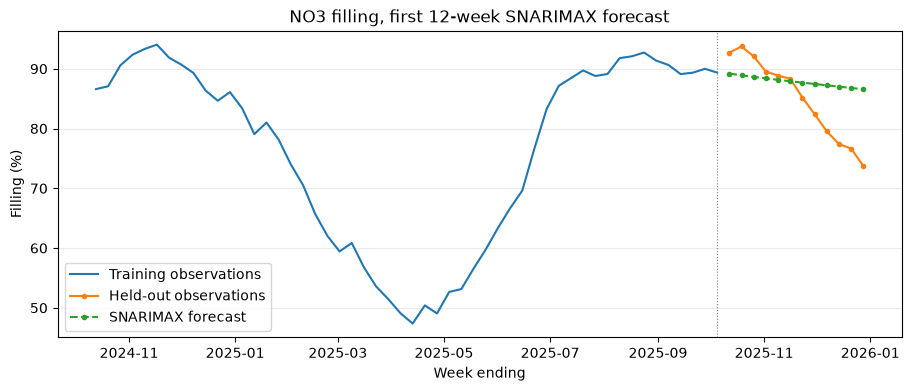

In [20]:
# Show the last year of training alongside the held-out weeks and forecasts.
fig, ax = plt.subplots(figsize=(9, 3.8), layout='constrained')
ax.plot(training_filling.tail(52).index, training_filling.tail(52) * 100, label='Training observations')
ax.plot(forecast_comparison.index, forecast_comparison['observed'] * 100,
        marker='.', label='Held-out observations')
ax.plot(first_forecast.index, first_forecast * 100, marker='.', linestyle='--', label='SNARIMAX forecast')
ax.axvline(training_filling.index[-1], color='0.5', linewidth=0.8, linestyle=':')
ax.set(title='NO3 filling, first 12-week SNARIMAX forecast',
       xlabel='Week ending', ylabel='Filling (%)')
ax.legend()
ax.grid(axis='y', alpha=0.25)
plt.show()

#### First-run findings

The initial p=3, d=1, q=3 model achieved a mean absolute error of **5.15 percentage points** and RMSE of **6.45 percentage points** over the 12 held-out weeks. It forecast **86.57%** filling for 28 December 2025, while the observed value was **73.75%**, an overestimate of **12.82 percentage points**. It predicted a gradual decline and underestimated the later fall.

This run demonstrates training on a selected region and period, a recursive multi-week forecast, and evaluation against held-out observations. The next experiments compare the initial result with the last observed filling, filling 52 weeks earlier, and seasonal SNARIMAX settings using chronological splits.